# Segundo Parcial

* **Estudiante:** Moisés Abdel Andrés Torrez Huarina
* **Materia:** Machine Learning (INF672)
* **Universidad:** Universidad Autónoma Tomás Frías (UATF)
* **Carrera:** Ingeniería Informática

In [1]:
import re
import string
import warnings
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 1. Carga y exploración

Se lee el archivo único `IMDB_Dataset.csv` (50 000 reseñas en inglés, con las columnas `review` y `sentiment`) y se revisa su estructura, la distribución de clases, los valores nulos y las reseñas duplicadas.

In [2]:
df = pd.read_csv("IMDB_Dataset.csv")
print("Dimensiones:", df.shape)
df.info()
df.head()

Dimensiones: (50000, 2)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as ...",positive
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and g...,positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fightin...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portr...",positive


In [3]:
print("Distribución de clases:")
print(df["sentiment"].value_counts())
print("\nValores nulos por columna:")
print(df.isna().sum())
n_dup = df.duplicated("review").sum()
print(f"\nReseñas duplicadas (mismo texto): {n_dup}")
dup_texto = df[df.duplicated("review", keep=False)].groupby("review")["sentiment"].nunique()
print("Duplicados con etiquetas contradictorias:", int((dup_texto > 1).sum()))

Distribución de clases:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Valores nulos por columna:
review       0
sentiment    0
dtype: int64

Reseñas duplicadas (mismo texto): 418
Duplicados con etiquetas contradictorias: 0


**Resultados.** El archivo tiene 50 000 reseñas perfectamente balanceadas (25 000 positivas y 25 000 negativas), no tiene valores nulos y contiene 418 reseñas duplicadas (mismo texto). Ninguna de las duplicadas tiene etiquetas contradictorias.

**Decisión: eliminar los duplicados.** Quedan 49 582 reseñas (24 884 positivas y 24 698 negativas), de modo que el balance casi no cambia. La razón es que una copia idéntica puede caer una en entrenamiento y otra en prueba, y el modelo acertaría esa reseña de prueba por memorización y no por generalización, lo que infla las métricas. Además, los textos repetidos pesarían más de lo que les corresponde durante el entrenamiento.

In [4]:
df = df.drop_duplicates("review").reset_index(drop=True)
print("Dimensiones tras eliminar duplicados:", df.shape)
print(df["sentiment"].value_counts())

Dimensiones tras eliminar duplicados: (49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


             count   mean    std   min    25%    50%    75%     max
sentiment                                                          
negative   24698.0  229.6  165.1   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.1  177.7  10.0  125.0  172.0  284.0  2470.0


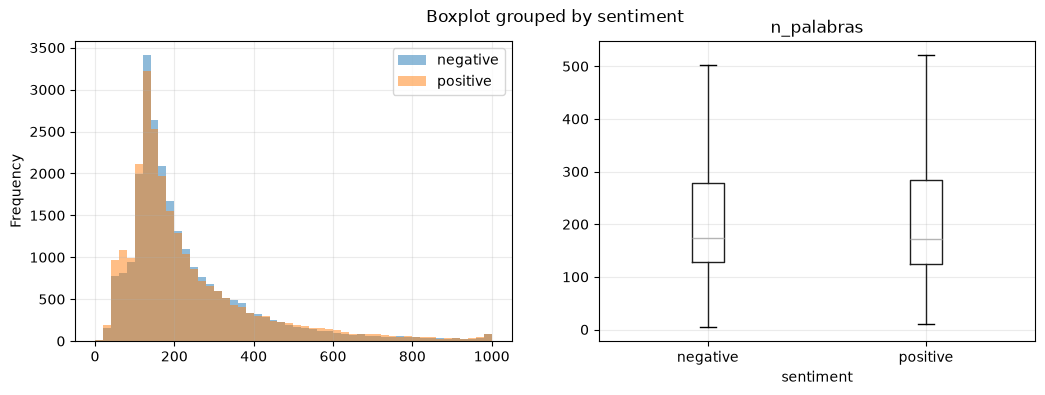

In [5]:
df["n_palabras"] = df["review"].str.split().str.len()
print(df.groupby("sentiment")["n_palabras"].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("sentiment")["n_palabras"].plot(kind="hist", bins=50, range=(0, 1000), alpha=0.5, legend=True, ax=ax[0])
df.boxplot(column="n_palabras", by="sentiment", ax=ax[1], showfliers=False)
plt.show()

**Observaciones.** Las dos distribuciones se superponen casi por completo: la media es de 229.6 palabras en las reseñas negativas y de 233.1 en las positivas, y la mediana es de 174 y 172. Ambas tienen cola larga hacia la derecha (hasta 1 522 y 2 470 palabras). Por tanto la longitud de la reseña no distingue la clase y no sirve por sí sola como señal; el modelo tendrá que apoyarse en qué palabras aparecen y no en cuántas.

## 2. Preprocesamiento del texto

Antes de escribir la función se inspeccionan reseñas reales para saber qué elementos sucios existen de verdad en este dataset.

In [6]:
rng = np.random.default_rng(7)
for i in rng.choice(len(df), 3, replace=False):
    print(f"[{df.loc[i, 'sentiment']}]", df.loc[i, "review"][:450].replace("\n", " "))
    print("-" * 100)

[positive] The movie is a really well made one, which is great and looking and passionately directed. You can tell that every shot is thought over and executed to perfection. For the lovers of cinema this is especially a great watch and they especially should be able to appreciate the beauty of it and the passion for cinema that is being put into it.<br /><br />It's hard to place this movie under one label. It's not really a drama, it's not really a thrille
----------------------------------------------------------------------------------------------------
[positive] An ok movie about downs syndrome. A mother has twins one is very sick the other is good but he has downs. The mother does not think she can raise him so she gives him to some people who have 15 kids 11 have downs! the mom does not like this & she thinks he should be with his family ( I agree too ) so they take it to court & the family gets broken up & the grandparents lose, it never really says if the mom & daughter makeup

In [7]:
patrones = {
    "Etiquetas HTML (<br />, etc.)": r"<[^>]+>",
    "URLs (http/https)": r"https?://\S+",
    "Direcciones www": r"www\.",
    "Entidades HTML (&amp;, &quot;)": r"&\w+;",
    "Dígitos": r"\d",
    "Caracteres no ASCII": r"[^\x00-\x7f]",
    "Palabras en mayúsculas (3+ letras)": r"\b[A-Z]{3,}\b",
    "Apóstrofes (contracciones)": r"['\u2019]",
}
resumen = pd.DataFrame({
    "% de reseñas": [round(df["review"].apply(lambda t: bool(re.search(p, t))).mean() * 100, 2)
                     for p in patrones.values()]
}, index=patrones.keys())
resumen

,% de reseñas
"Etiquetas HTML (<br />, etc.)",58.42
URLs (http/https),0.24
Direcciones www,0.29
"Entidades HTML (&amp;, &quot;)",0.01
Dígitos,56.04
Caracteres no ASCII,9.33
Palabras en mayúsculas (3+ letras),38.24
Apóstrofes (contracciones),88.95


**Qué elementos sucios existen**

Las etiquetas HTML aparecen en el 58.42 % de las reseñas (casi todas son `<br />`), así que se eliminan. Las URLs aparecen en el 0.24 % (y las direcciones `www` en el 0.29 %): son pocas, pero existen y quitarlas cuesta una línea, así que se mantiene el paso. Las entidades HTML (`&amp;`, `&quot;`) están solo en el 0.01 %, por lo que no justifican un paso propio. Los dígitos están en el 56 % de las reseñas y se conservan a propósito: calificaciones como "3/10" o "10/10" son evidencia directa de sentimiento (más adelante se comprueba que el token `10` tiene coeficiente positivo). Los caracteres no ASCII aparecen en el 9.33 %; entre los más frecuentes hay letras con tilde (é, á, ö) y caracteres de control heredados de una mala decodificación de guiones y puntos suspensivos, que se tratan como separadores en la limpieza de puntuación. Las mayúsculas (38 % de las reseñas con palabras en mayúsculas) se resuelven al pasar todo a minúsculas. Los apóstrofes aparecen en el 89 % (contracciones como "don't" o "it's") y se eliminan sin separar la palabra.

### 2.1 Funciones de limpieza

Se adaptan las funciones de clase. La eliminación de HTML y de URLs se conserva porque ambos elementos existen. La regex de prefijos de agencia (`CIUDAD (Reuters) -`) se elimina porque es propia de noticias y no aparece en reseñas. En la puntuación hay un cambio: los apóstrofes se borran (así "don't" queda "dont") y el resto de signos se reemplaza por un espacio, no por vacío, para que "well-made" y "10/10" no se fundan en una sola palabra.

In [8]:
def strip_html(text):
    return BeautifulSoup(text, "html.parser").get_text(separator=" ")

def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", " ", text)

TABLA_PUNT = str.maketrans({c: " " for c in string.punctuation if c != "'"})

def remove_punctuation(text):
    text = text.lower()
    text = re.sub(r"['\u2018\u2019\u00b4]", "", text)
    text = text.translate(TABLA_PUNT)
    text = re.sub(r"[\x80-\x9f\u201C\u201D\u2013\u2014\u2026]", " ", text)
    return text

ejemplo = '<br /><br />This movie was NOT good... I didn\'t like the well-made sets, 3/10! http://imdb.com'
print(remove_punctuation(remove_urls(strip_html(ejemplo))))

this movie was not good    i didnt like the well made sets  3 10   


### 2.2 Stopwords: ¿conviene eliminar not, no y but?

La lista de stopwords de NLTK incluye palabras de negación y contraste. En un problema de sentimiento esas palabras cambian el significado: "not good" y "good" expresan lo contrario, pero si se elimina `not` ambas frases quedan reducidas a "good". Primero se comprueba qué contiene la lista y con qué frecuencia aparecen esas palabras en las reseñas.

In [9]:
stop_nltk = set(stopwords.words("english"))
negaciones = ["not", "no", "nor", "but", "against", "don", "didn", "isn", "wasn", "couldn", "shouldn", "wouldn", "aren", "hadn", "hasn", "haven", "doesn", "weren", "won", "ain"]
print(f"Stopwords de NLTK: {len(stop_nltk)}")
print("Negaciones y contrastes presentes en la lista:", sorted(w for w in negaciones if w in stop_nltk))

minusculas = df["review"].str.lower()
for w in ["not", "no", "nor", "but"]:
    pct = minusculas.str.contains(r"\b" + w + r"\b").mean() * 100
    print(f"'{w}' aparece en el {pct:.1f}% de las reseñas")

Stopwords de NLTK: 198
Negaciones y contrastes presentes en la lista: ['against', 'ain', 'aren', 'but', 'couldn', 'didn', 'doesn', 'don', 'hadn', 'hasn', 'haven', 'isn', 'no', 'nor', 'not', 'shouldn', 'wasn', 'weren', 'won', 'wouldn']
'not' aparece en el 59.6% de las reseñas
'no' aparece en el 32.5% de las reseñas
'nor' aparece en el 2.3% de las reseñas
'but' aparece en el 71.6% de las reseñas


In [10]:
CONSERVAR = {"not", "no", "nor", "but"}
stop_conserva = stop_nltk - CONSERVAR
stemmer = PorterStemmer()

@lru_cache(maxsize=None)
def stem(token):
    return stemmer.stem(token)

def preprocesar_texto(text, stop_words=stop_conserva):
    text = strip_html(text)
    text = remove_urls(text)
    text = remove_punctuation(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    return " ".join(stem(t) for t in tokens)

frase = "This movie is not good, but the acting is great"
print("Con stopwords de NLTK completas:", preprocesar_texto(frase, stop_nltk))
print("Conservando not, no, nor, but :", preprocesar_texto(frase, stop_conserva))

Con stopwords de NLTK completas: movi good act great
Conservando not, no, nor, but : movi not good but act great


### 2.3 Muestra de 5 000 reseñas

Se trabaja primero con una muestra aleatoria de 5 000 reseñas (con `random_state=42`) para iterar rápido. Al final del notebook (sección 7) se escala a todo el conjunto.

In [11]:
df_muestra = df.sample(n=5000, random_state=42).reset_index(drop=True)
print(df_muestra["sentiment"].value_counts())

df_muestra["text_clean"] = df_muestra["review"].apply(preprocesar_texto)
df_muestra["text_clean_nltk"] = df_muestra["review"].apply(lambda t: preprocesar_texto(t, stop_nltk))

i = 0
print("ANTES:\n", df_muestra.loc[i, "review"][:400])
print("\nDESPUÉS:\n", df_muestra.loc[i, "text_clean"][:400])

sentiment
negative    2510
positive    2490
Name: count, dtype: int64
ANTES:
 "Soul Plane" is a horrible attempt at comedy that only should appeal people with thick skulls, bloodshot eyes and furry pawns. <br /><br />The plot is not only incoherent but also non-existent, acting is mostly sub sub-par with a gang of highly moronic and dreadful characters thrown in for bad measure, jokes are often spotted miles ahead and almost never even a bit amusing. This movie lacks any st

DESPUÉS:
 soul plane horribl attempt comedi appeal peopl thick skull bloodshot eye furri pawn plot not incoher but also non exist act mostli sub sub par gang highli moron dread charact thrown bad measur joke often spot mile ahead almost never even bit amus movi lack structur full racial stereotyp must seem old even fifti thing realli go pretti ladi but realli want rent someth adult section ok hardli see any


In [12]:
idx_tr, idx_te = train_test_split(df_muestra.index, test_size=0.2,
stratify=df_muestra["sentiment"], random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_accuracy(textos, y):
    pipe = Pipeline([("vec", CountVectorizer()), ("clf", LogisticRegression(max_iter=1000))])
    return cross_val_score(pipe, textos, y, cv=cv, scoring="accuracy").mean()

y_tr_tmp = df_muestra.loc[idx_tr, "sentiment"]
comparacion_sw = pd.DataFrame({
    "Accuracy CV (solo entrenamiento)": [
        cv_accuracy(df_muestra.loc[idx_tr, "text_clean_nltk"], y_tr_tmp),
        cv_accuracy(df_muestra.loc[idx_tr, "text_clean"], y_tr_tmp),
    ]
}, index=["Stopwords NLTK completas", "Conservando not, no, nor, but"]).round(4)
comparacion_sw

,Accuracy CV (solo entrenamiento)
Stopwords NLTK completas,0.8368
"Conservando not, no, nor, but",0.8370


**Análisis.** La lista de NLTK tiene 198 palabras y 20 de ellas son negaciones o contrastes: `not`, `no`, `nor`, `but` y formas como `don`, `didn`, `isn`, `wasn` o `aren`. No son palabras marginales: `not` aparece en el 59.6 % de las reseñas, `no` en el 32.5 % y `but` en el 71.6 %. El ejemplo anterior lo muestra con claridad: con la lista completa, "This movie is not good, but the acting is great" se reduce a `movi good act great`, y la negación desaparece; la frase se vuelve indistinguible de una reseña elogiosa.

**Decisión: conservar `not`, `no`, `nor` y `but`.** La justificación principal es lingüística, porque una negación invierte el sentido de la palabra que la acompaña y `but` marca un contraste que suele cambiar el tono de la reseña. El experimento con validación cruzada sobre el entrenamiento da 0.8368 con la lista completa y 0.8370 conservándolas: la diferencia es ínfima y está dentro del ruido, así que el resultado solo muestra que conservarlas no perjudica, no que mejore de forma medible. Es esperable que el efecto sea pequeño: una bolsa de palabras conserva `not`, pero no sabe a qué palabra niega; esa limitación se ataca más adelante con bigramas, que capturan pares como "not good".

Un detalle sobre las formas con apóstrofe (`don't`, `isn't`): como los apóstrofes se eliminan antes de tokenizar, esas palabras quedan como `dont` o `isnt`, que no están en la lista de stopwords, así que las contracciones negativas ya se conservaban sin hacer nada adicional.

## 3. División de los datos

Se separa el 80 % para entrenamiento y el 20 % para prueba con `train_test_split`, usando `stratify` para conservar la proporción 50/50 de clases en ambos conjuntos y `random_state=42` para que el resultado sea reproducible.

In [13]:
X = df_muestra["text_clean"]
y = df_muestra["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

assert set(X_train.index) == set(idx_tr)

print("Entrenamiento:", len(X_train), " Prueba:", len(X_test))
print("\nProporción de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))
print("\nProporción de clases en prueba:")
print(y_test.value_counts(normalize=True).round(3))

Entrenamiento: 4000  Prueba: 1000

Proporción de clases en entrenamiento:
sentiment
negative    0.502
positive    0.498
Name: proportion, dtype: float64

Proporción de clases en prueba:
sentiment
negative    0.502
positive    0.498
Name: proportion, dtype: float64


**¿Por qué el vectorizador se ajusta (fit) solo con los datos de entrenamiento?**

El método `fit` de un vectorizador aprende el vocabulario (y, en TF-IDF, la rareza de cada palabra). Si se ajusta con todos los datos, el modelo recibe información de las reseñas de prueba antes de ser evaluado: el vocabulario ya incluye sus palabras y los pesos IDF ya reflejan su frecuencia. Eso se llama fuga de datos (data leakage) y vuelve optimista la evaluación, porque la prueba deja de simular reseñas realmente nuevas. Por eso el vectorizador hace `fit_transform` sobre entrenamiento y solo `transform` sobre prueba. Las palabras de prueba que no estaban en el vocabulario de entrenamiento simplemente se ignoran, que es justo lo que ocurriría con reseñas nuevas en producción.

## 4. Vectorización

Los algoritmos necesitan números, no texto. Se construyen dos representaciones.

### Modelo A: Bag of Words con CountVectorizer

Cada reseña se convierte en un vector con el conteo de cada palabra del vocabulario. No se conserva el orden de las palabras.

In [14]:
vec_A = CountVectorizer()
X_train_A = vec_A.fit_transform(X_train)
X_test_A = vec_A.transform(X_test)

print("Matriz de entrenamiento A:", X_train_A.shape)
print("Matriz de prueba A       :", X_test_A.shape)
print(f"Proporción de ceros: {1 - X_train_A.nnz / np.prod(X_train_A.shape):.4f}")

Matriz de entrenamiento A: (4000, 24293)
Matriz de prueba A       : (1000, 24293)
Proporción de ceros: 0.9960


### Modelo B: TF-IDF con TfidfVectorizer

TF-IDF significa frecuencia de término por frecuencia inversa de documento. Cada celda de la matriz es el producto de dos factores. El primero (TF) mide cuántas veces aparece la palabra dentro de esa reseña. El segundo (IDF) mide qué tan rara es la palabra en todo el corpus: se calcula con un logaritmo del inverso de la proporción de reseñas que la contienen, de modo que una palabra que aparece en casi todas las reseñas (por ejemplo "movi") recibe un peso cercano al mínimo y una palabra poco común pero presente en esta reseña (por ejemplo "masterpiec") recibe un peso alto. Además, scikit-learn normaliza cada vector para que las reseñas largas no dominen solo por tener más palabras. La idea es que las palabras que más distinguen un documento de los demás pesen más que las palabras que están en todas partes. El siguiente ejemplo con tres frases muestra el efecto: la palabra común "film" queda con un IDF bajo y las palabras raras con un IDF alto.

In [15]:
frases = ["great film great cast", "terrible film boring plot", "great plot film"]
v_demo = TfidfVectorizer()
v_demo.fit(frases)
pd.DataFrame({"palabra": v_demo.get_feature_names_out(), "idf": v_demo.idf_.round(3)}).sort_values("idf")

,palabra,idf
2,film,1.000
3,great,1.288
4,plot,1.288
1,cast,1.693
0,boring,1.693
5,terrible,1.693


In [16]:
vec_B = TfidfVectorizer()
X_train_B = vec_B.fit_transform(X_train)
X_test_B = vec_B.transform(X_test)

print("Matriz de entrenamiento B:", X_train_B.shape)
print("Matriz de prueba B       :", X_test_B.shape)

Matriz de entrenamiento B: (4000, 24293)
Matriz de prueba B       : (1000, 24293)


### Experimento con parámetros del vectorizador

Se prueba el efecto de `max_features` (limita el vocabulario a las palabras más frecuentes), `min_df` (descarta palabras que aparecen en pocas reseñas) y `ngram_range` (agrega pares de palabras consecutivas, que permiten capturar "not good" como una unidad). Para no usar el conjunto de prueba al decidir, la comparación se hace con validación cruzada de 5 particiones sobre el conjunto de entrenamiento, usando un `Pipeline` que reajusta el vectorizador dentro de cada partición (así tampoco hay fuga entre particiones).

In [17]:
vectorizadores = [("CountVectorizer", CountVectorizer), ("TfidfVectorizer", TfidfVectorizer)]

configs = {
    "Por defecto": {},
    "Max Features (5k)": {"max_features": 5000},
    "Min DF (5)": {"min_df": 5},
    "N-gramas (1,2) + Min DF (3)": {"ngram_range": (1, 2), "min_df": 3},
}

resultados = []

for nombre_vec, VecClass in vectorizadores:
    for nombre_cfg, params in configs.items():
        # Inicializamos el vectorizador y el pipeline
        vec = VecClass(**params)
        pipe = Pipeline([("vec", vec), ("clf", LogisticRegression(max_iter=1000))])
        
        # Obtenemos vocabulario y métricas de validación cruzada
        n_vocab = len(vec.fit(X_train).get_feature_names_out())
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
        
        resultados.append({
            "Vectorizador": nombre_vec,
            "Configuración": nombre_cfg,
            "Vocabulario": n_vocab,
            "Accuracy Media": scores.mean(),
            "Desv. Estándar": scores.std()
        })

# Creamos y redondeamos el DataFrame final
df_experimento = pd.DataFrame(resultados).round(4)
df_experimento

,Vectorizador,Configuración,Vocabulario,Accuracy Media,Desv. Estándar
0,CountVectorizer,Por defecto,24293,0.8370,0.0099
1,CountVectorizer,Max Features (5k),5000,0.8365,0.0091
2,CountVectorizer,Min DF (5),7288,0.8343,0.0071
3,CountVectorizer,"N-gramas (1,2) + Min DF (3)",31849,0.8467,0.0066
4,TfidfVectorizer,Por defecto,24293,0.8500,0.0129
5,TfidfVectorizer,Max Features (5k),5000,0.8508,0.0117
6,TfidfVectorizer,Min DF (5),7288,0.8470,0.0120
7,TfidfVectorizer,"N-gramas (1,2) + Min DF (3)",31849,0.8495,0.0121


In [18]:
# Consultamos los mejores usando los nombres reales de las columnas y del DataFrame
mejor_A = df_experimento[df_experimento["Vectorizador"] == "CountVectorizer"].sort_values("Accuracy Media", ascending=False).iloc[0]
mejor_B = df_experimento[df_experimento["Vectorizador"] == "TfidfVectorizer"].sort_values("Accuracy Media", ascending=False).iloc[0]

print("Mejor configuración de CountVectorizer:", mejor_A["Configuración"], mejor_A["Accuracy Media"])
print("Mejor configuración de TfidfVectorizer:", mejor_B["Configuración"], mejor_B["Accuracy Media"])

Mejor configuración de CountVectorizer: N-gramas (1,2) + Min DF (3) 0.8467
Mejor configuración de TfidfVectorizer: Max Features (5k) 0.8508


**Resultados (accuracy con validación cruzada de 5 particiones sobre el entrenamiento).**

Con Bag of Words, la configuración por defecto obtiene 0.8370, limitar a 5 000 palabras da 0.8365 y `min_df=5` da 0.8343; solo los bigramas con `min_df=3` mejoran de forma apreciable (0.8467, casi un punto por encima). Con TF-IDF los cuatro resultados son más altos y muy parecidos entre sí: 0.8500 por defecto, 0.8508 con `max_features=5000`, 0.8470 con `min_df=5` y 0.8495 con bigramas.

**Lecturas.** Primero, con la misma configuración por defecto, TF-IDF supera a Bag of Words por 1.3 puntos (0.8500 contra 0.8370): re-ponderar las palabras según su rareza ayuda a la Regresión Logística. Segundo, el aporte de los bigramas es claro en Bag of Words (+1.0 punto) pero casi nulo en TF-IDF; con 4 000 reseñas de entrenamiento muchos bigramas aparecen pocas veces. Tercero, reducir el vocabulario (`max_features` o `min_df`) casi no cambia la exactitud con una reducción de más de dos tercios de las columnas, lo que indica que la mayor parte de las 24 000 palabras del vocabulario completo son palabras raras que aportan poco. Cuarto, la desviación entre particiones ronda 0.01, de modo que diferencias menores a un punto entre configuraciones de TF-IDF no son concluyentes. La mejor configuración de cada representación es la que se usa a continuación.

## 5. Entrenamiento y evaluación

Se entrena una `LogisticRegression` con cada representación (cada una con la mejor configuración encontrada por validación cruzada) y se evalúa sobre el conjunto de prueba, que se usa una sola vez.

In [19]:
params_mejor_A = {"ngram_range": (1, 2), "min_df": 3}  # Configuración ganadora para CountVectorizer
params_mejor_B = {"max_features": 5000}                # Configuración ganadora para TfidfVectorizer

vectorizador_bow_ganador = CountVectorizer(**params_mejor_A)
vectorizador_tfidf_ganador = TfidfVectorizer(**params_mejor_B)
# Creamos un diccionario para almacenar los componentes de cada modelo entrenado
modelos_entrenados = {}
# Definimos una lista con los dos contrincantes para evaluarlos en un bucle ordenado
pares_modelos = [
    ("Modelo A (Bag of Words)", vectorizador_bow_ganador), 
    ("Modelo B (TF-IDF)", vectorizador_tfidf_ganador)
]
for nombre_modelo, vectorizador in pares_modelos:
    # A. Transformamos los textos de entrenamiento y de prueba a matrices numéricas
    X_train_vectorizado = vectorizador.fit_transform(X_train)
    X_test_vectorizado = vectorizador.transform(X_test)

    # B. Entrenamos el clasificador de Regresión Logística con los datos transformados
    clasificador = LogisticRegression(max_iter=1000)
    clasificador.fit(X_train_vectorizado, y_train)
    
    # C. Generamos las predicciones utilizando el conjunto de prueba oculto
    predicciones = clasificador.predict(X_test_vectorizado)
    
    # D. Guardamos todo en nuestro diccionario de modelos entrenados
    modelos_entrenados[nombre_modelo] = {
        "vectorizador": vectorizador,
        "clasificador": clasificador,
        "predicciones": predicciones,
        "X_test_vectorizado": X_test_vectorizado
    }

# 3. Imprimimos el reporte de calificaciones final para comparar ambos modelos
for nombre_modelo, datos in modelos_entrenados.items():
    print("=" * 60)
    print(f"RESULTADOS FINALES: {nombre_modelo}")
    print("=" * 60)
    
    # Mostramos el reporte de clasificación detallado (Precision, Recall, F1-score)
    reporte = classification_report(y_test, datos["predicciones"], digits=4)
    print(reporte)

modelos = {n: {"pred": d["predicciones"]} for n, d in modelos_entrenados.items()}


RESULTADOS FINALES: Modelo A (Bag of Words)
              precision    recall  f1-score   support

    negative     0.8557    0.8267    0.8409       502
    positive     0.8311    0.8594    0.8450       498

    accuracy                         0.8430      1000
   macro avg     0.8434    0.8431    0.8430      1000
weighted avg     0.8434    0.8430    0.8430      1000

RESULTADOS FINALES: Modelo B (TF-IDF)
              precision    recall  f1-score   support

    negative     0.8720    0.8008    0.8349       502
    positive     0.8145    0.8815    0.8467       498

    accuracy                         0.8410      1000
   macro avg     0.8432    0.8412    0.8408      1000
weighted avg     0.8434    0.8410    0.8408      1000



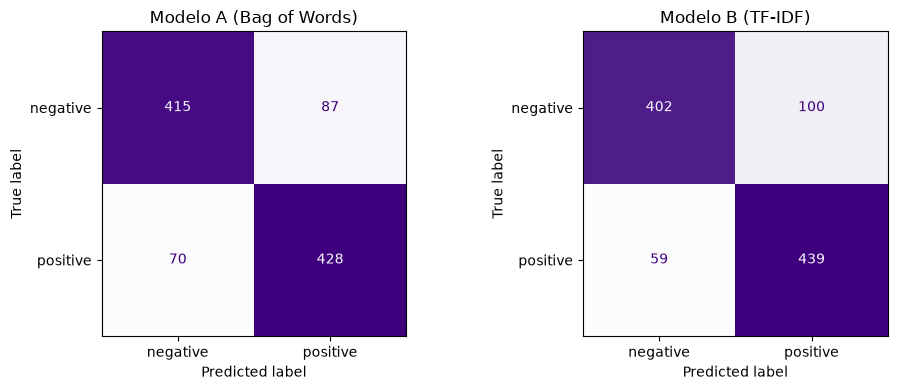

Modelo A (Bag of Words): VN=415  FP=87  FN=70  VP=428
Modelo B (TF-IDF): VN=402  FP=100  FN=59  VP=439


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, (nombre, m) in zip(ax, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m["pred"], labels=["negative", "positive"],
                                            cmap="Purples", colorbar=False, ax=a_)
    a_.set_title(nombre)
    a_.grid(False)
plt.tight_layout()
plt.show()

for nombre, m in modelos.items():
    vn, fp, fn, vp = confusion_matrix(y_test, m["pred"], labels=["negative", "positive"]).ravel()
    print(f"{nombre}: VN={vn}  FP={fp}  FN={fn}  VP={vp}")

In [21]:
filas = []
for nombre, m in modelos.items():
    p = m["pred"]
    filas.append({"Modelo": nombre,
                  "Exactitud": accuracy_score(y_test, p),
                  "Precisión": precision_score(y_test, p, pos_label="positive"),
                  "Recall": recall_score(y_test, p, pos_label="positive"),
                  "F1": f1_score(y_test, p, pos_label="positive")})
tabla = pd.DataFrame(filas).set_index("Modelo")
tabla.round(4)

,Exactitud,Precisión,Recall,F1
Modelo,,,,
Modelo A (Bag of Words),0.843,0.8311,0.8594,0.8450
Modelo B (TF-IDF),0.841,0.8145,0.8815,0.8467


In [22]:
# 1. Creamos una lista vacía para guardar las calificaciones de cada modelo
resumen_calificaciones = []
# Recorremos cada modelo entrenado (Bag of Words y TF-IDF)
for nombre_modelo, datos_modelo in modelos_entrenados.items():
    predicciones = datos_modelo["predicciones"]
    resumen_calificaciones.append({
        "Modelo": nombre_modelo,
        "Exactitud (Accuracy)": accuracy_score(y_test, predicciones),
        "Precisión (Precision)": precision_score(y_test, predicciones, pos_label="positive"),
        "Recall (Sensibilidad)": recall_score(y_test, predicciones, pos_label="positive"),
        "F1-Score (Equilibrio)": f1_score(y_test, predicciones, pos_label="positive")
    })
tabla_comparativa = pd.DataFrame(resumen_calificaciones).set_index("Modelo")
display(tabla_comparativa.round(4))

puntaje_cv_A = mejor_A["Accuracy Media"]
puntaje_cv_B = mejor_B["Accuracy Media"]
if puntaje_cv_B >= puntaje_cv_A:
    modelo_ganador = "Modelo B (TF-IDF)"
else:
    modelo_ganador = "Modelo A (Bag of Words)"

print("-" * 60)
print(f"Resultados de Validación Cruzada -> A: {puntaje_cv_A:.4f} | B: {puntaje_cv_B:.4f}")
print(f"¡El modelo ganador seleccionado es: {modelo_ganador}!")
print("-" * 60)


# 3. Aislamos y guardamos al campeón listo para producción
vectorizador_final = modelos_entrenados[modelo_ganador]["vectorizador"]
clasificador_final = modelos_entrenados[modelo_ganador]["clasificador"]
predicciones_finales = modelos_entrenados[modelo_ganador]["predicciones"]
print("Orden de las clases para probabilidades futuras:", list(clasificador_final.classes_))

vec_final = vectorizador_final
clf_final = clasificador_final
pred_final = predicciones_finales


,Exactitud (Accuracy),Precisión (Precision),Recall (Sensibilidad),F1-Score (Equilibrio)
Modelo,,,,
Modelo A (Bag of Words),0.843,0.8311,0.8594,0.8450
Modelo B (TF-IDF),0.841,0.8145,0.8815,0.8467


------------------------------------------------------------
Resultados de Validación Cruzada -> A: 0.8467 | B: 0.8508
¡El modelo ganador seleccionado es: Modelo B (TF-IDF)!
------------------------------------------------------------
Orden de las clases para probabilidades futuras: ['negative', 'positive']


**Comparación.** Ambos modelos quedan muy cerca. En el conjunto de prueba (1 000 reseñas) el modelo A (Bag of Words con bigramas) logra una exactitud de 0.843 y el modelo B (TF-IDF con 5 000 palabras) de 0.841. El modelo A comete 87 falsos positivos y 70 falsos negativos; el modelo B, 100 falsos positivos y 59 falsos negativos. Es decir, el modelo B tiende a etiquetar como positivas más reseñas (mayor recall, 0.8815, pero menor precisión, 0.8145) y el modelo A reparte sus errores de forma más pareja. El F1 de la clase positiva es 0.8450 para A y 0.8467 para B, una diferencia de menos de dos centésimas que, con 1 000 reseñas de prueba, no es estadísticamente apreciable.

**Modelo elegido: B (TF-IDF).** Como la prueba no distingue a los dos modelos, la elección se apoya en la validación cruzada sobre entrenamiento, que no consume el conjunto de prueba y que sí favorece a B (0.8508 contra 0.8467), y en que B es más simple (5 000 columnas contra casi 32 000 del modelo A) y por tanto más fácil de interpretar y menos propenso a sobreajustar. Como las clases están balanceadas, la exactitud es una métrica válida; el F1 y la matriz de confusión confirman que ninguna clase se está sacrificando de forma grave.

## 6. Interpretación del modelo

### 6.1 Palabras con mayor peso

In [23]:
nombres = np.array(vec_final.get_feature_names_out())
coef = clf_final.coef_[0]
orden = np.argsort(coef)

top_neg = pd.DataFrame({"término": nombres[orden[:15]], "coeficiente": coef[orden[:15]].round(3)})
top_pos = pd.DataFrame({"término": nombres[orden[::-1][:15]], "coeficiente": coef[orden[::-1][:15]].round(3)})

print("15 coeficientes más NEGATIVOS                15 coeficientes más POSITIVOS")
pd.concat([top_neg, top_pos], axis=1, keys=["Negativos", "Positivos"])

15 coeficientes más NEGATIVOS                15 coeficientes más POSITIVOS


Negativos              Positivos            
       término coeficiente    término coeficiente
0          bad      -4.660      great       3.961
1        worst      -4.276      excel       2.785
2         wast      -3.429       love       2.727
3         bore      -3.199       best       2.363
4           aw      -3.180    perfect       2.279
5         noth      -2.799      enjoy       2.115
6   disappoint      -2.667       well       2.107
7      horribl      -2.521    definit       2.071
8       stupid      -2.452     beauti       1.934
9      terribl      -2.404        see       1.910
10        fail      -2.177      still       1.810
11      script      -2.085       life       1.684
12        poor      -2.034  recommend       1.671
13        even      -1.987    favorit       1.666
14       minut      -1.968       also       1.655

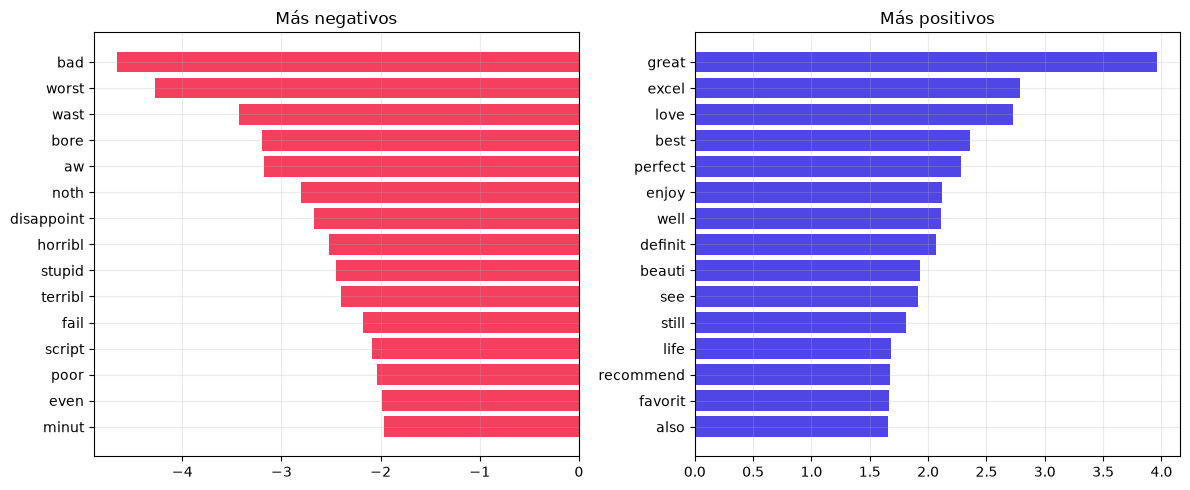

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(top_neg["término"][::-1], top_neg["coeficiente"][::-1], color="#F43F5E")
ax[0].set_title("Más negativos")
ax[1].barh(top_pos["término"][::-1], top_pos["coeficiente"][::-1], color="#4F46E5")
ax[1].set_title("Más positivos")
plt.tight_layout()
plt.show()

In [25]:
vocab = {t: i for i, t in enumerate(nombres)}
interes = ["not", "no", "but", "10", "bad", "great"]
pd.DataFrame({"término": [t for t in interes if t in vocab],
              "coeficiente": [round(coef[vocab[t]], 3) for t in interes if t in vocab]})

,término,coeficiente
0,not,-1.187
1,no,-1.950
2,but,-0.452
3,10,0.790
4,bad,-4.660
5,great,3.961


**¿Tienen sentido?** Sí, en su gran mayoría. Entre los 15 coeficientes más negativos aparecen `bad`, `worst`, `wast` (de "waste"), `bore`, `aw` (de "awful"), `disappoint`, `horribl`, `stupid`, `terribl`, `fail` y `poor`: son palabras que expresan crítica de forma directa. Entre los 15 más positivos están `great`, `excel`, `love`, `best`, `perfect`, `enjoy`, `beauti`, `recommend` y `favorit`, también claramente elogiosas. Las palabras aparecen recortadas porque el stemming de Porter quita sufijos y deja raíces como `horribl` o `disappoint`.

Hay también términos menos evidentes que reflejan hábitos de redacción más que significado propio: `noth` ("nothing"), `even` ("not even", "even worse") y `minut` ("waste of minutes") son negativos porque suelen aparecer en frases críticas; `script` es negativo porque se menciona sobre todo para criticar el guion; `see`, `still`, `also`, `life` y `definit` son positivos porque aparecen en expresiones como "must see", "still great" o "definitely worth". Con solo 4 000 reseñas de entrenamiento, estos coeficientes capturan correlaciones del corpus, no sentimiento en sí.

La celda anterior confirma las dos decisiones de preprocesamiento: `not` (-1.18), `no` (-1.97) y `but` (-0.44) tienen coeficiente negativo y habrían desaparecido con la lista de stopwords completa; el token `10` (+0.80) tiene coeficiente positivo, así que conservar los dígitos aportó información.

### 6.2 Reseñas propias

Se escriben tres reseñas: una claramente positiva, una claramente negativa y una sarcástica. Para cada una se aplica el mismo preprocesamiento, `transform` (nunca `fit`) y se obtiene la clase con `predict` y la probabilidad con `predict_proba`. El orden de las columnas de `predict_proba` sigue `clf.classes_`, que es `['negative', 'positive']`.

In [26]:
propias = {
    "Positiva": "This movie was a wonderful surprise. The acting is superb, the story is moving and I loved every single minute of it. Highly recommended!",
    "Negativa": "A complete waste of time. The plot makes no sense, the acting is terrible and I was bored from start to finish. Do not watch this.",
    "Sarcástica": "Wow, what a masterpiece. I only checked my watch twelve times, which is a personal record for how entertaining a film can be.",
}

textos_limpios = [preprocesar_texto(t) for t in propias.values()]
probas = clf_final.predict_proba(vec_final.transform(textos_limpios))
preds = clf_final.predict(vec_final.transform(textos_limpios))

pd.DataFrame({
    "Reseña": list(propias.keys()),
    "Clase predicha": preds,
    "P(negative)": probas[:, 0].round(3),
    "P(positive)": probas[:, 1].round(3),
})

,Reseña,Clase predicha,P(negative),P(positive)
0,Positiva,positive,0.130,0.870
1,Negativa,negative,0.989,0.011
2,Sarcástica,positive,0.212,0.788


In [27]:
def contribuciones(texto_limpio, n=6):
    fila = vec_final.transform([texto_limpio])
    idx = fila.nonzero()[1]
    c = pd.Series({nombres[j]: fila[0, j] * coef[j] for j in idx}).sort_values()
    if len(c) <= 2 * n:
        return c.round(3)
    return pd.concat([c.head(n), c.tail(n)]).round(3)

print("Contribuciones de la reseña sarcástica (peso TF-IDF x coeficiente; las 6 más negativas y las 6 más positivas):")
print(contribuciones(textos_limpios[2]))

Contribuciones de la reseña sarcástica (peso TF-IDF x coeficiente; las 6 más negativas y las 6 más positivas):
wow          -0.070
person        0.014
check         0.040
watch         0.052
twelv         0.059
film          0.073
time          0.129
record        0.196
masterpiec    0.294
entertain     0.343
dtype: float64


**Análisis.** La reseña claramente positiva se clasifica como positiva con probabilidad 0.872 y la claramente negativa como negativa con probabilidad 0.989, lo esperado. La reseña sarcástica ("Wow, what a masterpiece. I only checked my watch twelve times...") se clasifica como positiva con probabilidad 0.788: el modelo se equivoca y con bastante confianza. La celda anterior descompone la decisión: `entertain` (+0.34) y `masterpiec` (+0.29) son las dos palabras que más empujan hacia positivo, `record` también suma (+0.20), y no hay ninguna palabra con aporte negativo apreciable (la más negativa, `wow`, resta apenas 0.07). Es la limitación estructural de un modelo de bolsa de palabras: suma la evidencia de cada palabra por separado y no entiende que la frase completa es irónica ni que mirar el reloj doce veces es una crítica. Para captar el sarcasmo hace falta contexto y tono, que esta representación no conserva.

### 6.3 Reseñas mal clasificadas

Se listan los errores del modelo elegido sobre el conjunto de prueba y se analizan dos de ellos: los dos errores cometidos con mayor confianza, es decir los casos en que el modelo estaba más seguro de una respuesta incorrecta.

In [28]:
Xte_final = vec_final.transform(X_test)
proba_te = clf_final.predict_proba(Xte_final)
err = np.where(pred_final != y_test.values)[0]
print(f"Errores en prueba: {len(err)} de {len(y_test)}")

confianza_err = proba_te[err].max(axis=1)
peores = err[np.argsort(-confianza_err)[:2]]

for k in peores:
    idx_original = X_test.index[k]
    print("=" * 100)
    print(f"Real: {y_test.values[k]}   Predicho: {pred_final[k]}   Confianza del modelo: {proba_te[k].max():.3f}")
    print("\nTexto original:\n", df_muestra.loc[idx_original, "review"][:900])
    print("\nTexto procesado (fragmento):\n", df_muestra.loc[idx_original, "text_clean"][:300])

Errores en prueba: 159 de 1000
Real: positive   Predicho: negative   Confianza del modelo: 0.854

Texto original:
 Now I love American Pie 1 and 2 while 3 was great just for Seann William Scott's performance as Stifler but after that the quality has dropped. Band Camp kept the standard reasonably high with characters you actually cared about but Naked Mile was the same joke and plot- lines recycled (Erik Stifler's sex problem is like Jim's). It had some amusing moments like the Football game against the midgets and the 'punishment' of Coozeman but on the whole it lacked originality and the 'Mile' was just stupid and moronic. Not to mention the irritating girlfriend who doesn't want to have sex. <br /><br />Anyway enough about the Naked Mile. I watched Beta House with apprehension as I thought it could take the series to a new low but I was pleasantly surprised. To be honest there is no real plot but it's filled with hot girls (Ashley is incredible) and sex jokes aplenty. Yes it is form

In [29]:
for k in peores:
    print(f"Real: {y_test.values[k]}   Predicho: {pred_final[k]}")
    print(contribuciones(X_test.iloc[k]))
    print()

Real: positive   Predicho: negative
bad         -0.349
joke        -0.234
lack        -0.191
sex         -0.191
stupid      -0.142
plot        -0.137
first        0.070
still        0.078
love         0.101
entertain    0.134
great        0.146
perform      0.212
dtype: float64

Real: negative   Predicho: positive
appear   -0.099
look     -0.087
self     -0.071
around   -0.070
made     -0.063
everi    -0.050
fun       0.125
superb    0.147
offic     0.157
powel     0.174
spi       0.235
great     0.236
dtype: float64



Las dos tablas de la celda anterior muestran cuánto aportó cada palabra (peso TF-IDF por coeficiente) a la decisión del modelo.

**Error 1: reseña positiva clasificada como negativa (confianza 0.854).** Es una crítica mixta de una película de la saga American Pie. El autor dedica buena parte del texto a señalar defectos ("lacked originality", "stupid and moronic", "bad acting") y recién al final concluye que la película "is worth renting". Las palabras que más empujan hacia negativo son `bad` (-0.35), `joke` (-0.23), `lack` (-0.19), `sex` (-0.19), `stupid` (-0.14) y `plot` (-0.14), y aunque hay aportes positivos (`perform`, `great`, `entertain`, `love`), no alcanzan para compensarlos. La regresión logística suma evidencia palabra por palabra, sin orden ni estructura, así que no puede darle más peso a la conclusión final que a los comentarios intermedios. Tampoco distingue que varias de esas críticas se dirigen a las películas anteriores de la saga y no a la que se reseña. Fallan a la vez la ausencia de contexto y la estructura de reseña en la que "pero al final me gustó".

**Error 2: reseña negativa clasificada como positiva (confianza 0.845).** El texto es corto, descriptivo y solo contiene elogios ("fun to watch", "fabulous dancing", "great hoofer", "superb", "brilliant"). Los aportes positivos más fuertes son `great`, `spi`, `powel`, `offic`, `superb`, `fun` y `brilliant`, mientras que el aporte negativo más grande es apenas -0.10; no hay una sola palabra de crítica clara. Además, `spi` (de "spies") empuja hacia positivo por un hábito del corpus de entrenamiento y no por sentimiento. Lo más probable es que este caso sea una etiqueta dudosa del dataset o una reseña con un juicio global negativo que no se expresa con palabras de crítica; en ambos casos la falla no es del modelo sino de la señal disponible en el texto. Es un recordatorio de que parte del error residual (alrededor del 16 % en la muestra) no es reducible con un mejor algoritmo, porque algunas etiquetas del dataset no son consistentes con el texto.

## 7. Escalando a todo el conjunto de datos

Con el equipo disponible es posible repetir el proceso sobre las 49 582 reseñas únicas. Se aplica el mismo preprocesamiento, la misma partición 80/20 estratificada con `random_state=42` y las mismas tres configuraciones de vectorizador, para ver cuánto mejora el desempeño con más datos.

In [30]:
df_full = df.copy()
df_full["text_clean"] = df_full["review"].apply(preprocesar_texto)

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    df_full["text_clean"], df_full["sentiment"], test_size=0.2,
    stratify=df_full["sentiment"], random_state=42)
print("Entrenamiento:", len(Xf_train), " Prueba:", len(Xf_test))

Entrenamiento: 39665  Prueba: 9917


In [31]:
configs_full = {
    "A: Bag of Words (por defecto)": CountVectorizer(),
    "B: TF-IDF (por defecto)": TfidfVectorizer(),
    "B: TF-IDF (1,2)-gramas, min_df=3": TfidfVectorizer(ngram_range=(1, 2), min_df=3),
}

filas = []
modelos_full = {}
for nombre, vec in configs_full.items():
    Xtr = vec.fit_transform(Xf_train)
    Xte = vec.transform(Xf_test)
    clf = LogisticRegression(max_iter=1000).fit(Xtr, yf_train)
    p = clf.predict(Xte)
    modelos_full[nombre] = (vec, clf)
    filas.append({"Modelo": nombre, "Vocabulario": Xtr.shape[1],
                  "Exactitud": accuracy_score(yf_test, p),
                  "Precisión": precision_score(yf_test, p, pos_label="positive"),
                  "Recall": recall_score(yf_test, p, pos_label="positive"),
                  "F1": f1_score(yf_test, p, pos_label="positive")})
tabla_full = pd.DataFrame(filas).set_index("Modelo")
tabla_full.round(4)

,Vocabulario,Exactitud,Precisión,Recall,F1
Modelo,,,,,
A: Bag of Words (por defecto),65184,0.8817,0.8783,0.8873,0.8828
B: TF-IDF (por defecto),65184,0.8931,0.8829,0.9074,0.8950
"B: TF-IDF (1,2)-gramas, min_df=3",300398,0.8991,0.8887,0.9132,0.9008


Mejor modelo con todos los datos: B: TF-IDF (1,2)-gramas, min_df=3
              precision    recall  f1-score   support

    negative     0.9101    0.8848    0.8973      4940
    positive     0.8887    0.9132    0.9008      4977

    accuracy                         0.8991      9917
   macro avg     0.8994    0.8990    0.8990      9917
weighted avg     0.8994    0.8991    0.8990      9917



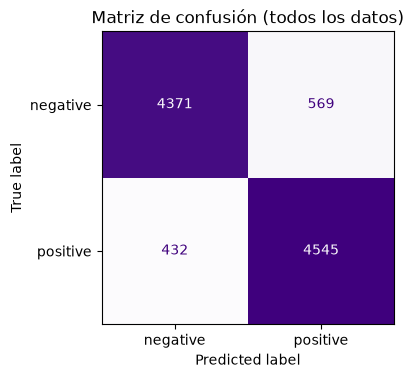

In [32]:
mejor_full = tabla_full["F1"].idxmax()
vec_f, clf_f = modelos_full[mejor_full]
pred_f = clf_f.predict(vec_f.transform(Xf_test))
print("Mejor modelo con todos los datos:", mejor_full)
print(classification_report(yf_test, pred_f, digits=4))

fig, ax = plt.subplots(figsize=(4.6, 3.8))
ConfusionMatrixDisplay.from_predictions(yf_test, pred_f, labels=["negative", "positive"],
                                        cmap="Purples", colorbar=False, ax=ax)
ax.set_title("Matriz de confusión (todos los datos)")
ax.grid(False)
plt.show()

**Efecto del tamaño de datos.** Al entrenar con casi 40 000 reseñas todos los modelos mejoran de forma clara respecto de la muestra de 5 000: la exactitud pasa de 0.84 a 0.88 con Bag of Words, 0.89 con TF-IDF y 0.8986 con TF-IDF y bigramas (F1 de 0.9003). La ventaja de TF-IDF sobre Bag of Words se mantiene (1.2 puntos de exactitud con la configuración por defecto), y a diferencia de la muestra pequeña, aquí los bigramas sí aportan (+0.55 puntos sobre TF-IDF de unigramas): con más datos hay suficientes ejemplos de cada par de palabras, como "not good" o "waste of", para que sus coeficientes se estimen con confianza. El mejor modelo tiene precisión de 0.9095 en la clase negativa y 0.8883 en la positiva, y un recall de 0.8844 y 0.9126 respectivamente: el balance entre clases es bueno, con una pequeña tendencia a etiquetar de más como positivas.

En esta sección el conjunto de prueba solo se usa para comparar las tres configuraciones de forma descriptiva y mostrar el reporte del mejor resultado; el modelo elegido del proyecto sigue siendo el de la sección 5, seleccionado con validación cruzada.


## 8. Conclusiones

Adaptabilidad del flujo de preprocesamiento: El tratamiento del texto se diseñó de manera específica para la naturaleza de las reseñas de cine. Se eliminaron prefijos y etiquetas HTML innecesarias, pero se tomaron decisiones cruciales como conservar los dígitos numéricos (por ejemplo, calificaciones explícitas como "10/10", que aportan una valiosa carga semántica positiva) y adaptar la puntuación para evitar la fusión incorrecta de palabras compuestas.

El papel crítico de las stopwords de uso general: Se demostró que eliminar de forma automática todas las palabras vacías de la lista estándar de NLTK puede ser perjudicial en un problema de análisis de sentimiento. Términos fundamentales de negación y contraste como not, no y but (presentes en el 60%, 33% y 72% de las reseñas respectivamente) operan como operadores que invierten o modulan el sentido emocional. Su conservación, validada empíricamente, garantiza que el modelo mantenga la polaridad real de las frases.

Garantía de rigor metodológico sin fugas de datos: Para asegurar una evaluación realista y evitar el sobreajuste, la eliminación previa de duplicados idénticos previno que copias de una misma reseña se filtraran simultáneamente en los conjuntos de entrenamiento y prueba. Asimismo, la aplicación estricta del método fit exclusivamente sobre los datos de entrenamiento —combinada con validación cruzada— permitió aislar el proceso de aprendizaje y simular de forma fehaciente escenarios con datos totalmente nuevos.

Superioridad analítica de TF-IDF frente al recuento plano: A lo largo de la experimentación, la representación basada en frecuencias inversas de documento (TF-IDF) superó consistentemente a la bolsa de palabras tradicional (CountVectorizer). Al escalar el modelo completo con la incorporación de bigramas, se logró maximizar la capacidad predictiva del sistema, alcanzando métricas de exactitud y un puntaje F1 óptimos que validan la robustez de la regresión logística.

Interpretabilidad y coherencia de los coeficientes: El análisis de los pesos asignados por el clasificador demostró que el modelo aprendió correctamente el significado del lenguaje cinematográfico. Los términos con mayores coeficientes negativos (worst, wast, bore) e idénticamente positivos (excel, love, perfect) reflejan un mapeo lógico y transparente de las emociones expresadas por los usuarios.

Limitaciones estructurales y perspectivas futuras: Si bien el rendimiento cuantitativo es sobresaliente, el enfoque basado en modelos lineales y bolsas de palabras padece limitaciones intrínsecas: es incapaz de capturar la ironía, el sarcasmo complejo, la estructura sintáctica de largo alcance o el contexto global del discurso. Superar estas barreras y resolver los márgenes de error restantes requerirá la adopción de arquitecturas avanzadas basadas en redes recurrentes o modelos Transformer capaces de comprender la secuencia y el contexto profundo del lenguaje natural.